# Inciso 3: MLflow con un pipeline de scikit-learn

Sección de la documentación usada: *MLflow scikit-learn guide*, Advanced Features, pestaña **Pipeline Integration**.
La guía indica que `mlflow.sklearn.autolog()` registra los parámetros de cada paso de un `Pipeline`, las métricas de `score` y el modelo completo, y que con `GridSearchCV` crea un run hijo por cada combinación probada.

Pipeline usado: el de churn del Taller 2 (`Talleres/Taller2/pipeline`, paquete `data_prep_pipeline`), que se instala con `pip install -e ../Taller2/pipeline`.
Es un `Pipeline` de dos pasos: `preprocessing` (un `ColumnTransformer` con imputación, escalado y one-hot) y `classifier`.

Requiere el servidor de MLflow activo en `http://127.0.0.1:5000`.

In [1]:
import logging
import os
import warnings

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

import mlflow
from data_prep_pipeline import (
    build_cleaning_pipeline,
    build_model_pipeline,
    evaluate_model,
    load_raw_data,
    resolve_data_source,
    split_dataset,
    tune_model,
)

logging.getLogger("mlflow").setLevel(logging.ERROR)
for name in list(logging.root.manager.loggerDict):
    if name.startswith("mlflow"):
        logging.getLogger(name).setLevel(logging.ERROR)

TRACKING_URI = "http://127.0.0.1:5000"
EXPERIMENT_NAME = "Churn Pipeline"

mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENT_NAME)

<Experiment: artifact_location='/Users/diego/Uvg/MLEng/portfolio/Talleres/Taller3/mlartifacts/2', creation_time=1791933942520, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1791933942520, lifecycle_stage='active', name='Churn Pipeline', tags={}, trace_location=None, workspace='default'>

## 1. Datos

In [2]:
raw_df = load_raw_data(resolve_data_source())
clean_df = build_cleaning_pipeline().fit_transform(raw_df)
X_train, X_test, y_train, y_test = split_dataset(clean_df)
print(f"raw={raw_df.shape} clean={clean_df.shape} train={X_train.shape} test={X_test.shape}")
print(f"churn rate train={y_train.mean():.3f}")

raw=(7043, 21) clean=(7043, 20) train=(5634, 19) test=(1409, 19)
churn rate train=0.265


## 2. Autolog sobre un pipeline

Se activa `mlflow.sklearn.autolog()` **antes** de entrenar. Al llamar `fit` sobre el pipeline, MLflow crea un run y registra:

- los parámetros de todo el pipeline, con prefijo por paso (`classifier__n_estimators`, `preprocessing__preprocessor__numeric__imputer__strategy`, ...),
- las métricas de entrenamiento (`training_score`, `training_roc_auc`, `training_f1_score`, ...),
- el pipeline completo como modelo, con su firma y ejemplo de entrada.

Después se calculan las métricas sobre el set de prueba con `evaluate_model` del paquete y se agregan al mismo run.

In [3]:
mlflow.sklearn.autolog(log_input_examples=True, log_model_signatures=True)


def fit_and_log(run_name, estimator):
    pipeline = build_model_pipeline(estimator)
    with mlflow.start_run(run_name=run_name) as run:
        pipeline.fit(X_train, y_train)
        test_metrics = evaluate_model(pipeline, X_test, y_test)
        mlflow.log_metrics({f"test_{name}": value for name, value in vars(test_metrics).items()})
        mlflow.set_tag("variant", run_name)
    print(f"{run_name}: {test_metrics}")
    return run.info.run_id, pipeline


gradient_boosting_run_id, gradient_boosting_pipeline = fit_and_log(
    "gradient_boosting_default",
    GradientBoostingClassifier(learning_rate=0.1, max_depth=2, n_estimators=100, random_state=42),
)
logistic_run_id, _ = fit_and_log("logistic_regression", LogisticRegression(max_iter=1000))

gradient_boosting_default: accuracy=0.8013 precision=0.6655 recall=0.5053 f1=0.5745 roc_auc=0.8458


logistic_regression: accuracy=0.8055 precision=0.6572 recall=0.5588 f1=0.6040 roc_auc=0.8419


## 3. Pipeline dentro de una búsqueda de hiperparámetros

`tune_model` del paquete ejecuta `GridSearchCV` sobre el pipeline completo. Con autolog activo, MLflow crea un run padre con el mejor resultado y un run hijo por cada combinación de la rejilla, con sus puntajes de validación cruzada.

In [4]:
with mlflow.start_run(run_name="grid_search_gradient_boosting") as search_run:
    tuning_result = tune_model("gradient_boosting", X_train, y_train, search_type="grid", cv=3)
    test_metrics = evaluate_model(tuning_result.best_estimator, X_test, y_test)
    mlflow.log_metrics({f"test_{name}": value for name, value in vars(test_metrics).items()})
    mlflow.set_tag("variant", "grid_search_gradient_boosting")

print("best params:", tuning_result.best_params)
print(f"best cv roc_auc: {tuning_result.best_cv_score:.4f}")
print("test:", test_metrics)

best params: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 2, 'classifier__n_estimators': 100}
best cv roc_auc: 0.8492
test: accuracy=0.8013 precision=0.6655 recall=0.5053 f1=0.5745 roc_auc=0.8458


## 4. Qué quedó registrado

In [5]:
experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
runs = mlflow.search_runs(experiment_ids=[experiment.experiment_id])
n_children = runs["tags.mlflow.parentRunId"].notna().sum()
print(f"total runs={len(runs)}, child runs from GridSearchCV={n_children}")

parents = runs[runs["tags.mlflow.parentRunId"].isna()]
test_metrics_table = parents.set_index("tags.mlflow.runName").filter(like="metrics.test_").round(4)
test_metrics_table.columns = [c.removeprefix("metrics.test_") for c in test_metrics_table.columns]
test_metrics_table.index.name = "run"
test_metrics_table[["roc_auc", "f1", "recall", "precision", "accuracy"]]

total runs=8, child runs from GridSearchCV=5


,roc_auc,f1,recall,precision,accuracy
run,,,,,
grid_search_gradient_boosting,0.8458,0.5745,0.5053,0.6655,0.8013
logistic_regression,0.8419,0.6040,0.5588,0.6572,0.8055
gradient_boosting_default,0.8458,0.5745,0.5053,0.6655,0.8013


In [6]:
default_run = runs[runs["tags.mlflow.runName"] == "gradient_boosting_default"]
all_params = default_run.filter(like="params.").dropna(axis=1).iloc[0]
print(f"{len(all_params)} parameters logged by autolog for this run. Classifier parameters:")
classifier_params = all_params.filter(like="params.classifier__")
classifier_params.index = classifier_params.index.str.removeprefix("params.")
classifier_params.to_frame("value")

75 parameters logged by autolog for this run. Classifier parameters:


,value
classifier__init,None
classifier__criterion,deprecated
classifier__n_estimators,100
classifier__validation_fraction,0.1
classifier__max_depth,2
classifier__ccp_alpha,0.0
classifier__warm_start,False
classifier__min_samples_leaf,1
classifier__max_features,None
classifier__random_state,42


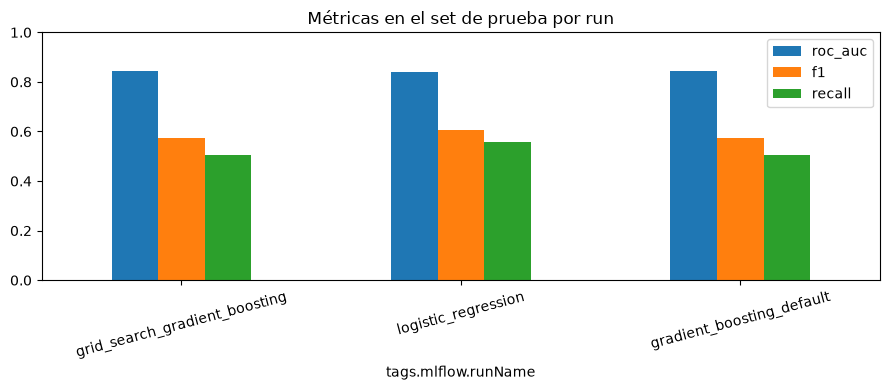

In [7]:
comparison = parents.set_index("tags.mlflow.runName")[
    ["metrics.test_roc_auc", "metrics.test_f1", "metrics.test_recall"]
].dropna()
comparison.columns = ["roc_auc", "f1", "recall"]
comparison.plot.bar(figsize=(9, 4), rot=15)
plt.title("Métricas en el set de prueba por run")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## 5. Cargar el modelo registrado y predecir

El pipeline se guardó completo, preprocesamiento incluido. Se carga desde el run y recibe filas crudas, sin pasos manuales previos.

In [8]:
loaded_pipeline = mlflow.sklearn.load_model(f"runs:/{gradient_boosting_run_id}/model")
print([name for name, _ in loaded_pipeline.steps])

pyfunc_model = mlflow.pyfunc.load_model(f"runs:/{gradient_boosting_run_id}/model")
sample = X_test.head(5)
pd.DataFrame(
    {
        "churn_pyfunc": pyfunc_model.predict(sample),
        "churn_real": y_test.head(5).to_numpy(),
    },
    index=sample.index,
)

['preprocessing', 'classifier']


,churn_pyfunc,churn_real
437,0,0
2280,1,0
2235,0,0
4460,0,0
3761,0,0
